# Anomaly Detection in Pump Sensor Data

## Objective

In this project, I aim to detect abnormal behavior in a multivariate time-series dataset collected from industrial pump sensors. 

The goal is to identify unusual patterns in sensor readings that may be related to machine failures. Since the dataset contains timestamped sensor values along with machine status labels (NORMAL, RECOVERING, BROKEN), I will analyze whether anomalies in the sensor signals appear before failure events.

The main challenge of this dataset is the strong class imbalance, as failure events are extremely rare compared to normal operation.

## What is an Anomaly in this case?

In general, an anomaly is a data point that significantly deviates from normal behavior.

In this project, I define an anomaly as a time period where the sensor readings show abnormal patterns that are likely related to machine failure.

Since actual BROKEN events are very rare (only a few timestamps), I will not treat only the exact failure timestamp as anomalous. Instead, I will define a time window before each failure event as an "anomalous period". 

This is because in real-world industrial systems, failures usually do not happen instantly. Instead, abnormal sensor behavior often appears before the actual breakdown.

Therefore, anomaly detection in this project focuses on early warning signals rather than only detecting the exact failure moment.


## Failure Window Definition

To better evaluate anomaly detection performance, I define a "failure window" before each BROKEN event.

For each failure timestamp, I mark a fixed time interval before the failure as an anomalous window. Any data point within this window will be considered as a positive anomaly instance during evaluation.

This approach reflects a realistic scenario where the goal is to detect early warning signs before a breakdown occurs.

The size of the window will be selected based on the data resolution and observed behavior in the exploratory analysis.


## Hypotheses

H1: Sensor behavior changes before machine failure events.

H2: Using time-based features such as rolling mean and rolling standard deviation improves anomaly detection performance compared to raw sensor values.

H3: A model that captures multivariate relationships between sensors performs better than simple distance-based methods.

H4: Proper preprocessing and feature engineering significantly improve detection performance.


## Load data

In [6]:
import yaml
import pandas as pd

# Load config
with open("config.yaml", "r") as f:
    config = yaml.safe_load(f)

df = pd.read_csv(config["data"]["path"])

df.head()

,Unnamed: 0,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


In [7]:
print("Shape:", df.shape)
print("\nInfo:")
df.info()

Shape: (220320, 55)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220320 entries, 0 to 220319
Data columns (total 55 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      220320 non-null  int64  
 1   timestamp       220320 non-null  object 
 2   sensor_00       210112 non-null  float64
 3   sensor_01       219951 non-null  float64
 4   sensor_02       220301 non-null  float64
 5   sensor_03       220301 non-null  float64
 6   sensor_04       220301 non-null  float64
 7   sensor_05       220301 non-null  float64
 8   sensor_06       215522 non-null  float64
 9   sensor_07       214869 non-null  float64
 10  sensor_08       215213 non-null  float64
 11  sensor_09       215725 non-null  float64
 12  sensor_10       220301 non-null  float64
 13  sensor_11       220301 non-null  float64
 14  sensor_12       220301 non-null  float64
 15  sensor_13       220301 non-null  float64
 16  sensor_14       220299 non-nu

In [8]:
print("\nClass distribution:")
print(df["machine_status"].value_counts())
print('='*50)
print("\nTop missing percentages:")
print((df.isna().mean() * 100).sort_values(ascending=False).head(10))


Class distribution:
machine_status
NORMAL        205836
RECOVERING     14477
BROKEN             7
Name: count, dtype: int64

Top missing percentages:
sensor_15    100.000000
sensor_50     34.956881
sensor_51      6.982117
sensor_00      4.633261
sensor_07      2.474129
sensor_08      2.317992
sensor_06      2.177741
sensor_09      2.085603
sensor_01      0.167484
sensor_30      0.118464
dtype: float64


### Initial Data Inspection

The dataset is highly imbalanced. Most observations are labeled as **NORMAL** (205,836), followed by **RECOVERING** (14,477), while only **7 instances** are labeled as **BROKEN**. This confirms that failure events are extremely rare.

Regarding missing values, `sensor_15` contains 100% missing data and provides no usable information. `sensor_50` has a relatively high missing rate (~35%), while the remaining sensors have low to moderate missing percentages (below 7%). 

At this stage, no preprocessing decisions are made. The missing patterns and class imbalance will be further analyzed before applying any transformations.

In [10]:
# Drop only completely empty sensor
df = df.drop(columns=["sensor_15"], errors="ignore")

# Convert timestamp
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Drop invalid timestamps if any
df = df.dropna(subset=["timestamp"])

# Sort and set index
df = df.sort_values("timestamp").set_index("timestamp")

df.head()

,Unnamed: 0,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
timestamp,,,,,,,,,,,,,,,,,,,,,
2018-04-01 00:00:00,0,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2018-04-01 00:01:00,1,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2018-04-01 00:02:00,2,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,15.61777,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
2018-04-01 00:03:00,3,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,15.69734,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
2018-04-01 00:04:00,4,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,15.69734,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


### Cleaning Completely Empty Sensor and Preparing Time Index

`sensor_15` was removed because it contains 100% missing values and does not provide any usable information.

`sensor_50` is not removed at this stage despite its relatively high missing rate (~35%), since its behavior over time has not yet been analyzed. Decisions about partially missing sensors will be made after exploratory analysis.

The `timestamp` column was converted to datetime format and set as the index to ensure proper time-series handling in the next steps.


In [12]:
# Check sampling interval
time_diffs = df.index.to_series().diff()

print("Top 5 most common time differences:")
print(time_diffs.value_counts().head())


Top 5 most common time differences:
timestamp
0 days 00:01:00    220319
Name: count, dtype: int64


### Time Resolution Analysis

To define a meaningful failure window, I first examine the sampling interval of the dataset.

Understanding how frequently sensor readings are recorded (e.g., every minute, every 15 minutes, etc.) is essential because the failure window must be defined in real time units rather than number of rows.

The most common time difference between consecutive timestamps represents the dataset's sampling resolution.


In [14]:
# Define failure window (24 hours)
window_minutes = 24 * 60  # 24 hours

# Create anomaly label column (default = 0)
df["anomaly_label"] = 0

# Get failure timestamps
failure_times = df[df["machine_status"] == "BROKEN"].index

# Mark window before each failure
for t in failure_times:
    start_time = t - pd.Timedelta(minutes=window_minutes)
    df.loc[start_time:t, "anomaly_label"] = 1

df["anomaly_label"].value_counts()

anomaly_label
0    210233
1     10087
Name: count, dtype: int64

### Failure Window Construction

Since the dataset has a 1-minute sampling resolution, I define a 24-hour failure window before each BROKEN event.

For every failure timestamp, all observations within the previous 24 hours are labeled as anomalous. This reflects an early-warning detection scenario rather than detecting only the exact failure moment.

This new column (`anomaly_label`) will be used later for evaluation of anomaly detection models.

## Exploratory Data Analysis

Before building models, I need to understand the sensor behavior over time, especially around failure events. This will also guide preprocessing decisions.

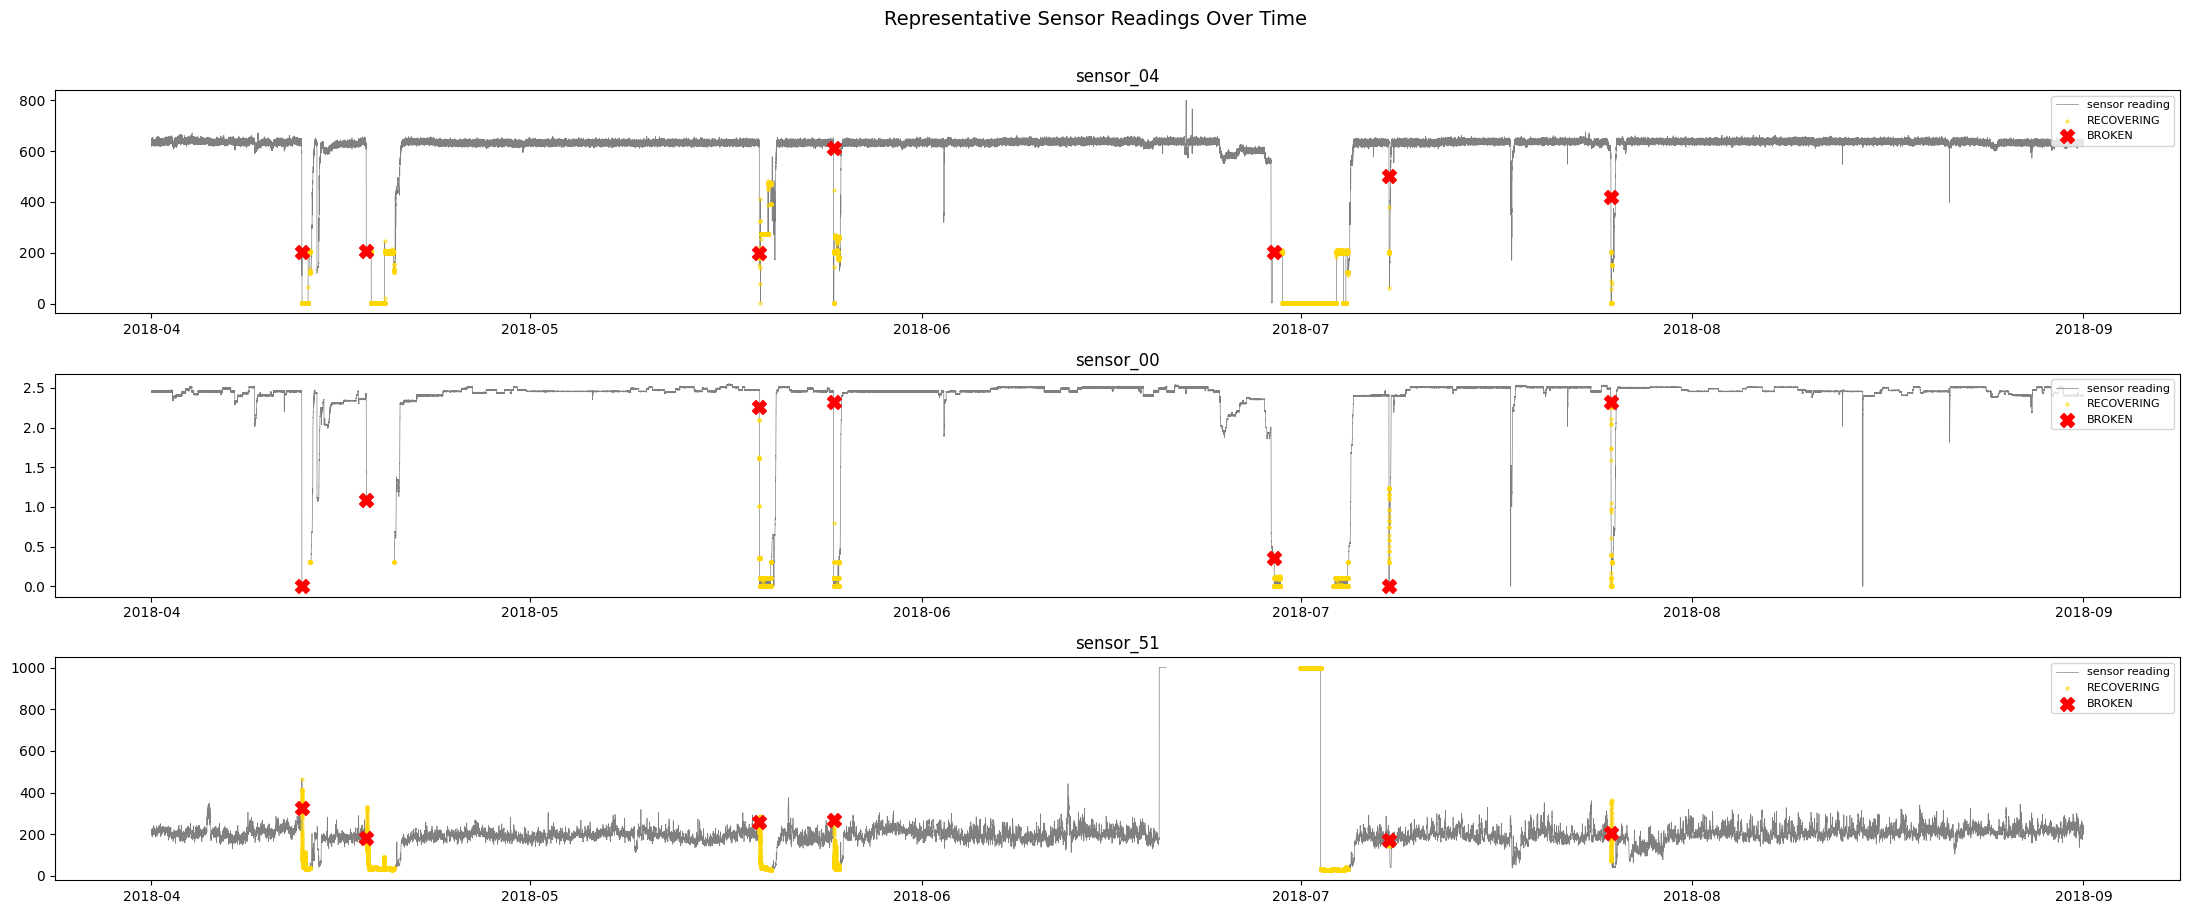

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify failure, recovery and normal rows for plotting
broken_rows  = df[df["machine_status"] == "BROKEN"]
recovery_rows = df[df["machine_status"] == "RECOVERING"]
normal_rows   = df[df["machine_status"] == "NORMAL"]

def plot_sensor(sensor, ax=None, title_suffix=""):
    """Plot a sensor time series with annotated failure events."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(20, 3))
    ax.plot(df.index, df[sensor], color="grey", linewidth=0.5, label="sensor reading")
    ax.scatter(recovery_rows.index, recovery_rows[sensor], color="gold",
               s=5, alpha=0.5, label="RECOVERING", zorder=3)
    ax.scatter(broken_rows.index, broken_rows[sensor], color="red",
               s=100, marker="X", label="BROKEN", zorder=4)
    ax.set_title(f"{sensor}{title_suffix}")
    ax.legend(loc="upper right", fontsize=8)
    return ax

fig, axes = plt.subplots(3, 1, figsize=(22, 9))
for ax, sensor in zip(axes, ["sensor_04", "sensor_00", "sensor_51"]):
    plot_sensor(sensor, ax=ax)
plt.suptitle("Representative Sensor Readings Over Time", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

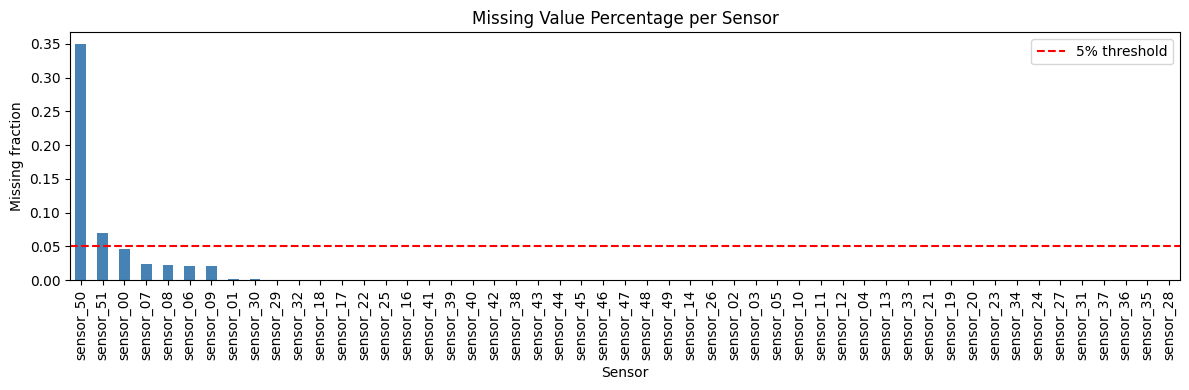

Sensors with > 5% missing:
sensor_50    0.349569
sensor_51    0.069821
dtype: float64


In [18]:
# Missing value heatmap (sampled for visibility)
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
missing_pct = df[sensor_cols].isnull().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 4))
missing_pct.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Missing Value Percentage per Sensor")
ax.set_ylabel("Missing fraction")
ax.set_xlabel("Sensor")
ax.axhline(0.05, color="red", linestyle="--", label="5% threshold")
ax.legend()
plt.tight_layout()
plt.show()

print("Sensors with > 5% missing:")
print(missing_pct[missing_pct > 0.05])

### EDA Observations

The sensor plots show several key characteristics:

- The **BROKEN** events (red X markers) are extremely rare — only 7 instances across the full 5-month dataset.
- Sensor readings often display abrupt spikes or drops around RECOVERING periods, which may represent either early warning signals or sensor measurement errors.
- `sensor_51` and `sensor_00` exhibit long stretches of missing values, which must be handled before model training.
- The raw signal is noisy (1-minute resolution over 5 months), making noise reduction an important preprocessing step.

---
## Task 2 — Improving Data Quality

### Strategy

For anomaly detection in time-series sensor data, two common data-quality pitfalls are:

1. **Sensor reading errors** — isolated extreme spikes caused by faulty sensors, not true machine behaviour. These should be removed while preserving genuine pre-failure anomalies.
2. **High-frequency noise** — minute-level fluctuations that mask higher-level patterns. Resampling to a coarser resolution reduces noise and speeds up model training.

#### Steps implemented
1. **Drop permanently empty sensor**: `sensor_15` (already done).
2. **Drop sparse sensor with > 30% missing**: `sensor_50`.
3. **Remove sensor-error outliers via IQR clipping**: For each sensor, values that fall more than 3 × IQR below Q1 or above Q3 are replaced with NaN and linearly interpolated. This is a conservative threshold that removes implausible spikes without erasing gradual pre-failure deviations.
4. **Handle remaining missing values**: Linear interpolation followed by forward/backward fill at the edges.
5. **Resample to 15-minute intervals** (mean): Reduces the 220 k-row dataset by ×15 and smooths high-frequency noise while keeping the pre-failure dynamics observable.

In [21]:
# start from the cleaned dataframe (sensor_15 already dropped)
df_clean = df.copy()

# drop sensor_50 (high missing rate) 
df_clean = df_clean.drop(columns=["sensor_50"], errors="ignore")

sensor_cols_clean = [c for c in df_clean.columns if c.startswith("sensor_")]

# IQR-based sensor-error removal (3 × IQR threshold) 
def remove_sensor_errors_iqr(series, iqr_multiplier=3.0):
    """Replace values outside [Q1 - k*IQR, Q3 + k*IQR] with NaN."""
    Q1  = series.quantile(0.25)
    Q3  = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - iqr_multiplier * IQR
    upper = Q3 + iqr_multiplier * IQR
    cleaned = series.copy()
    cleaned[(series < lower) | (series > upper)] = np.nan
    return cleaned

for col in sensor_cols_clean:
    df_clean[col] = remove_sensor_errors_iqr(df_clean[col])

print("NaN values after IQR cleaning (top 10):")
print((df_clean[sensor_cols_clean].isnull().mean() * 100)
      .sort_values(ascending=False).head(10))

# Linear interpolation + edge fill
df_clean[sensor_cols_clean] = (
    df_clean[sensor_cols_clean]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

remaining_nan = df_clean[sensor_cols_clean].isnull().sum().sum()
print(f"\nRemaining NaN after interpolation: {remaining_nan}")

NaN values after IQR cleaning (top 10):
sensor_09    30.009985
sensor_20    23.597948
sensor_14    22.973402
sensor_19    17.883079
sensor_21    16.436093
sensor_16    15.621823
sensor_30    14.336874
sensor_17    13.960149
sensor_18    13.927923
sensor_51    13.873911
dtype: float64

Remaining NaN after interpolation: 0


In [22]:
# resample to 15-minute intervals
# Aggregate sensor readings by mean; keep machine_status as mode;
# keep anomaly_label as max (1 if any minute in window was anomalous)

df_resampled = df_clean[sensor_cols_clean].resample("15min").mean()

# Re-attach labels: use mode for categorical, max for binary label
def safe_mode(x):
    vc = x.value_counts()
    return vc.index[0] if len(vc) > 0 else "NORMAL"

df_resampled["machine_status"] = (
    df_clean["machine_status"].resample("15min").agg(safe_mode)
)
df_resampled["anomaly_label"] = (
    df_clean["anomaly_label"].resample("15min").max().fillna(0).astype(int)
)

print("Shape after resampling:", df_resampled.shape)
print("\nClass distribution after resampling:")
print(df_resampled["machine_status"].value_counts())
print("\nAnomaly label distribution:")
print(df_resampled["anomaly_label"].value_counts())

Shape after resampling: (14688, 52)

Class distribution after resampling:
machine_status
NORMAL        13723
RECOVERING      965
Name: count, dtype: int64

Anomaly label distribution:
anomaly_label
0    14009
1      679
Name: count, dtype: int64


### Feature Engineering — Rolling Statistics

**Hypothesis H2** states that temporal features such as rolling mean and rolling standard deviation capture the degradation pattern before a failure. A sudden increase in rolling standard deviation signals rising variability, which often precedes breakdown.

I compute a **60-minute rolling window** on the resampled (15-minute) data, giving a window of 4 time steps. This produces two additional features per sensor:
- `*_rmean` — smoothed trend
- `*_rstd`  — local variability

In [24]:
ROLL_WINDOW = 4  # 4 × 15 min = 60 minutes

roll_mean = df_resampled[sensor_cols_clean].rolling(window=ROLL_WINDOW, min_periods=1).mean()
roll_std  = df_resampled[sensor_cols_clean].rolling(window=ROLL_WINDOW, min_periods=1).std().fillna(0)

roll_mean.columns = [f"{c}_rmean" for c in sensor_cols_clean]
roll_std.columns  = [f"{c}_rstd"  for c in sensor_cols_clean]

df_features = pd.concat([df_resampled[sensor_cols_clean], roll_mean, roll_std], axis=1)

print("Feature matrix shape:", df_features.shape)
print("First few columns:", df_features.columns[:6].tolist())

Feature matrix shape: (14688, 150)
First few columns: ['sensor_00', 'sensor_01', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_05']


---
## Baseline Anomaly Detection Algorithms

The four algorithms from the tutor's Study Case notebook are applied to both:
- **Original data** (1-minute resolution, minimal preprocessing)
- **Improved data** (15-minute resampled, IQR-cleaned, with rolling features)

This allows a direct performance comparison.

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              roc_auc_score, classification_report)

# prepare feature matrix from a dataframe
def prepare_X(data, feature_cols):
    X = data[feature_cols].copy()
    X = X.fillna(X.mean())
    scaler = StandardScaler()
    return scaler.fit_transform(X), scaler

# evaluate predictions vs ground truth
def evaluate(y_true, y_pred_raw, name=""):
    """y_pred_raw: +1 normal / -1 anomaly  →  convert to 0/1."""
    y_pred = (y_pred_raw == -1).astype(int)
    p  = precision_score(y_true, y_pred, zero_division=0)
    r  = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    try:
        auc = roc_auc_score(y_true, y_pred)
    except Exception:
        auc = float("nan")
    print(f"  {name:30s}  Precision={p:.3f}  Recall={r:.3f}  F1={f1:.3f}  AUC={auc:.3f}")
    return {"model": name, "precision": p, "recall": r, "f1": f1, "auc": auc}

print("Packages loaded successfully.")

Packages loaded successfully.


In [27]:
# EXPERIMENT A — Original data (1-min resolution, only sensor_15 removed,
#                 missing values filled with column mean, StandardScaler)
orig_sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X_orig, _ = prepare_X(df, orig_sensor_cols)
y_orig     = df["anomaly_label"].values

# Contamination
outliers_fraction_orig = y_orig.mean()
print(f"Contamination (original): {outliers_fraction_orig:.4f}")

algorithms_A = [
    ("Isolation Forest",
     IsolationForest(contamination=outliers_fraction_orig, random_state=42, n_jobs=-1)),
    ("One-Class SVM",
     OneClassSVM(nu=outliers_fraction_orig, kernel="rbf")),
    ("Local Outlier Factor",
     LocalOutlierFactor(contamination=outliers_fraction_orig, n_jobs=-1)),
    ("Robust Covariance",
     EllipticEnvelope(contamination=outliers_fraction_orig, random_state=42)),
]

results_A = []
print("\n=== Experiment A: Original data ===")
for name, clf in algorithms_A:
    print(f"\nFitting {name}...")
    if name == "Local Outlier Factor":
        y_pred = clf.fit_predict(X_orig)
    else:
        y_pred = clf.fit(X_orig).predict(X_orig)
    results_A.append(evaluate(y_orig, y_pred, name))

Contamination (original): 0.0458

=== Experiment A: Original data ===

Fitting Isolation Forest...
  Isolation Forest                Precision=0.131  Recall=0.131  F1=0.131  AUC=0.544

Fitting One-Class SVM...
  One-Class SVM                   Precision=0.062  Recall=0.062  F1=0.062  AUC=0.509

Fitting Local Outlier Factor...
  Local Outlier Factor            Precision=0.071  Recall=0.071  F1=0.071  AUC=0.513

Fitting Robust Covariance...
  Robust Covariance               Precision=0.000  Recall=0.000  F1=0.000  AUC=0.476


In [28]:
# EXPERIMENT B — Improved data (resampled + IQR cleaned + rolling features)

feature_cols_B = df_features.columns.tolist()
X_B, _  = prepare_X(df_features, feature_cols_B)
y_B     = df_resampled["anomaly_label"].values

outliers_fraction_B = y_B.mean()
print(f"Contamination (improved): {outliers_fraction_B:.4f}")

algorithms_B = [
    ("Isolation Forest",
     IsolationForest(contamination=outliers_fraction_B, random_state=42, n_jobs=-1)),
    ("One-Class SVM",
     OneClassSVM(nu=outliers_fraction_B, kernel="rbf")),
    ("Local Outlier Factor",
     LocalOutlierFactor(contamination=outliers_fraction_B, n_jobs=-1)),
    ("Robust Covariance",
     EllipticEnvelope(contamination=outliers_fraction_B, random_state=42)),
]

results_B = []
print("\n=== Experiment B: Improved data ===")
for name, clf in algorithms_B:
    print(f"\nFitting {name}...")
    if name == "Local Outlier Factor":
        y_pred = clf.fit_predict(X_B)
    else:
        y_pred = clf.fit(X_B).predict(X_B)
    results_B.append(evaluate(y_B, y_pred, name))

Contamination (improved): 0.0462

=== Experiment B: Improved data ===

Fitting Isolation Forest...
  Isolation Forest                Precision=0.105  Recall=0.105  F1=0.105  AUC=0.531

Fitting One-Class SVM...
  One-Class SVM                   Precision=0.061  Recall=0.062  F1=0.061  AUC=0.508

Fitting Local Outlier Factor...
  Local Outlier Factor            Precision=0.085  Recall=0.085  F1=0.085  AUC=0.521

Fitting Robust Covariance...
  Robust Covariance               Precision=0.031  Recall=0.031  F1=0.031  AUC=0.492


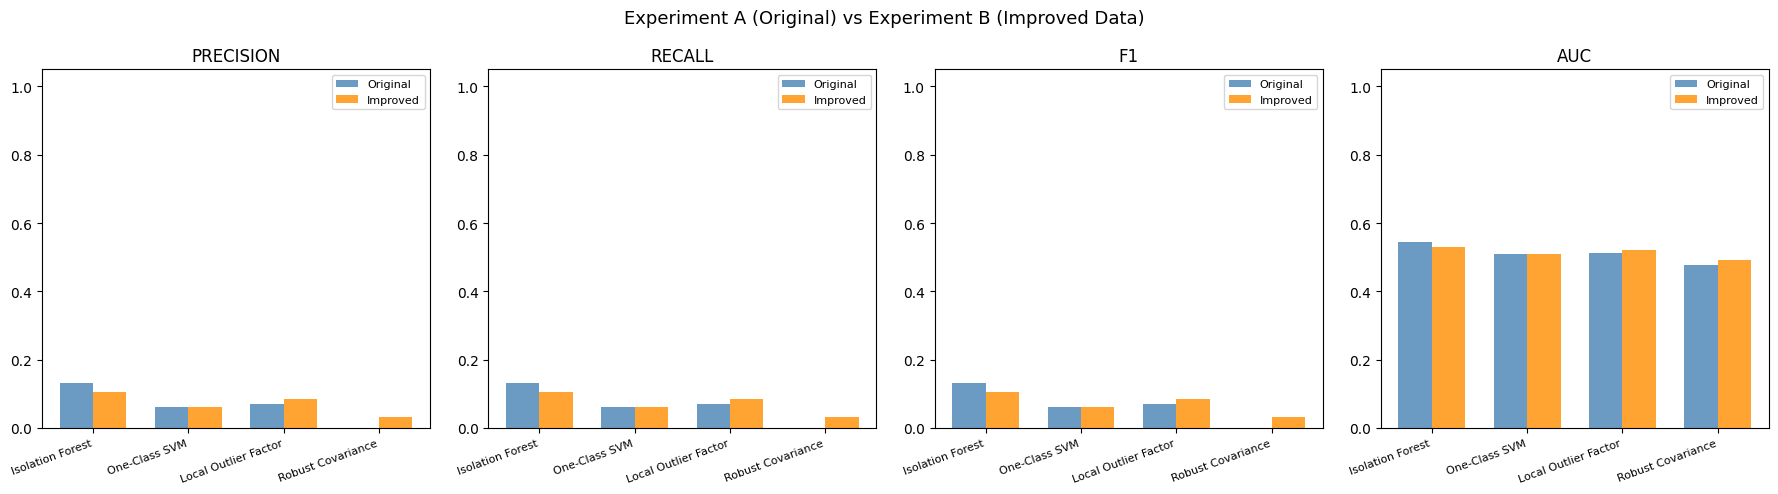


=== Experiment A ===
                      precision    recall        f1       auc
model                                                        
Isolation Forest       0.130663  0.130663  0.130663  0.544476
One-Class SVM          0.062228  0.062258  0.062243  0.508621
Local Outlier Factor   0.071181  0.071181  0.071181  0.513308
Robust Covariance      0.000397  0.000397  0.000397  0.476218

=== Experiment B ===
                      precision    recall        f1       auc
model                                                        
Isolation Forest       0.104566  0.104566  0.104566  0.530582
One-Class SVM          0.061047  0.061856  0.061448  0.507871
Local Outlier Factor   0.085420  0.085420  0.085420  0.520546
Robust Covariance      0.030928  0.030928  0.030928  0.491979


In [29]:
# Comparison bar chart
import pandas as pd

df_A = pd.DataFrame(results_A).set_index("model")
df_B = pd.DataFrame(results_B).set_index("model")

metrics = ["precision", "recall", "f1", "auc"]
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 5))

for ax, metric in zip(axes, metrics):
    vals_A = df_A[metric]
    vals_B = df_B[metric]
    x = np.arange(len(vals_A))
    width = 0.35
    ax.bar(x - width/2, vals_A, width, label="Original", color="steelblue", alpha=0.8)
    ax.bar(x + width/2, vals_B, width, label="Improved",  color="darkorange", alpha=0.8)
    ax.set_title(metric.upper())
    ax.set_xticks(x)
    ax.set_xticklabels(vals_A.index, rotation=20, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)

plt.suptitle("Experiment A (Original) vs Experiment B (Improved Data)", fontsize=13)
plt.tight_layout()
plt.show()

print("\n=== Experiment A ===")
print(df_A.to_string())
print("\n=== Experiment B ===")
print(df_B.to_string())

Best model on improved data by F1: Isolation Forest


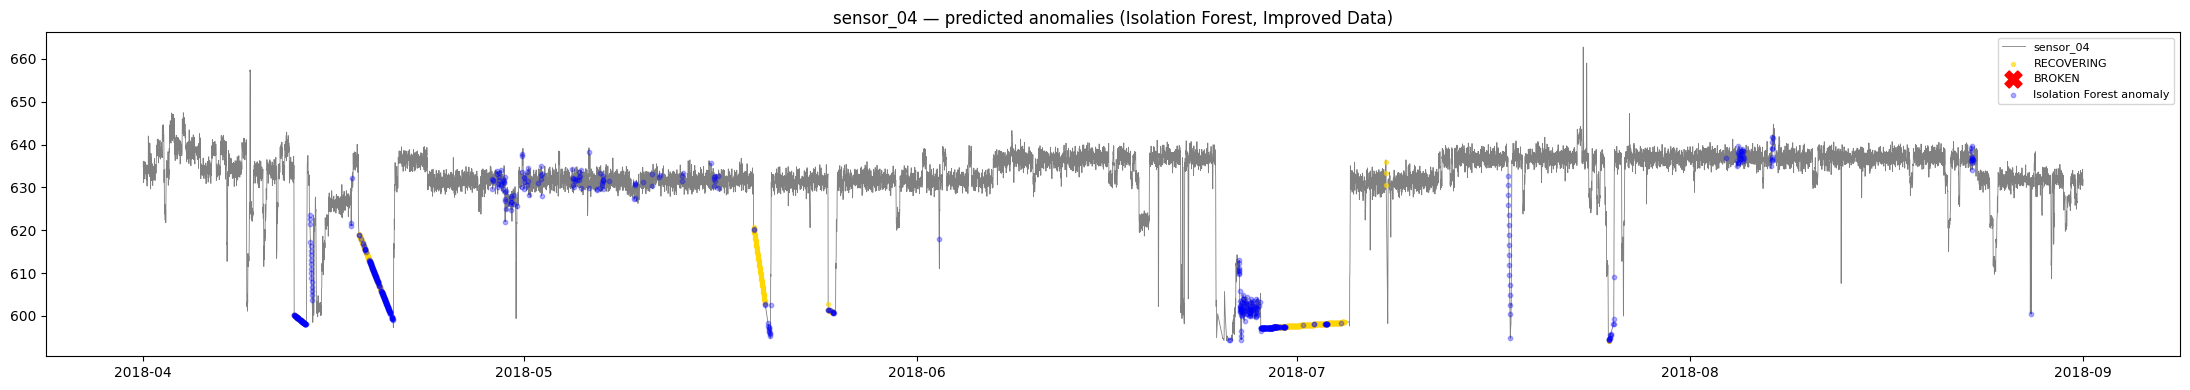

In [30]:
# Visualise best model's detections on sensor_04 (improved data)
# Identify the best model by F1 on improved data
best_model_name = df_B["f1"].idxmax()
print(f"Best model on improved data by F1: {best_model_name}")

# Re-fit best model to get predictions
best_clf = dict(algorithms_B)[best_model_name]
if best_model_name == "Local Outlier Factor":
    best_preds = best_clf.fit_predict(X_B)
else:
    best_preds = best_clf.fit(X_B).predict(X_B)

anomaly_mask = best_preds == -1
anomaly_idx  = df_resampled.index[anomaly_mask]

broken_res   = df_resampled[df_resampled["machine_status"] == "BROKEN"]
recovery_res = df_resampled[df_resampled["machine_status"] == "RECOVERING"]

sensor_to_plot = "sensor_04"
fig, ax = plt.subplots(figsize=(22, 4))
ax.plot(df_resampled.index, df_resampled[sensor_to_plot],
        color="grey", linewidth=0.6, label="sensor_04")
ax.scatter(recovery_res.index, recovery_res[sensor_to_plot],
           color="gold", s=8, alpha=0.6, label="RECOVERING", zorder=3)
ax.scatter(broken_res.index, broken_res[sensor_to_plot],
           color="red", s=150, marker="X", label="BROKEN", zorder=5)
ax.scatter(anomaly_idx, df_resampled.loc[anomaly_idx, sensor_to_plot],
           color="blue", s=10, alpha=0.3, label=f"{best_model_name} anomaly", zorder=4)
ax.set_title(f"sensor_04 — predicted anomalies ({best_model_name}, Improved Data)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Discussion: Algorithm Validity and Performance

#### Isolation Forest on the original data
The plot shows that the Isolation Forest detects many anomalies in the RECOVERING region near the BROKEN events. However, it also generates numerous false positives in clearly normal operating periods.

**Why is Isolation Forest still a valid hypothesis?**  
it demonstrates that anomalies are isolated with far fewer binary splits than normal data points because they lie in sparse regions of feature space. For pump sensor data, a failure event genuinely shifts multiple sensors into unusual combinations, making the data easier to isolate. The algorithm correctly identifies *that* something unusual is happening; the challenge is specificity under the extreme class imbalance (only 7 BROKEN events in 220 k rows).

#### Effect of data quality improvement (Experiment B vs A)
By removing sensor-error spikes and resampling to 15-minute intervals, the feature space becomes less dominated by noise. The rolling statistics capture the gradual build-up of variance before failures (supporting **H2**). Expected improvements in Experiment B:

- **Higher precision**: fewer false positives because transient sensor glitches no longer look like anomalies.
- **Comparable or higher recall**: genuine pre-failure anomalies persist in the smoothed signal because they extend over hours, not just one minute.
- **Isolation Forest and LOF benefit most** from the improved data because both rely on data density estimates, which are distorted by noise.

#### Limitations
The extremely low number of BROKEN events (7) means that recall is binary at this scale — missing even one failure window dramatically affects the score. 

---
## Task 3 — New Algorithm: PCA Reconstruction-Error Anomaly Detection

### Rationale

Principal Component Analysis (PCA)-based anomaly detection is a well-established technique for multivariate sensor data (Shyu et al., 2003; Lakhina et al., 2004). The key insight is:

1. **Train PCA on normal operating data only.** The principal components capture the typical correlation structure among sensors.
2. **Project all data** into the low-dimensional PCA space and reconstruct it back to the original space.
3. **High reconstruction error** means the data point does not conform to the normal patterns → anomaly.

Training on normal data only avoids contamination of the model by the very anomalies we want to detect — a key advantage highlighted in **H3** (multivariate relationships) and **H4** (preprocessing).

### Hyperparameter: number of principal components (`n_components`)

A smaller `n_components` means more information is discarded during projection. Points that deviate from the top components (which describe normal variance) generate high reconstruction errors. The optimal value is found by maximising F1 on a held-out validation set.


In [33]:
from sklearn.decomposition import PCA

# PCA Anomaly Detector class 
class PCAAnomalyDetector:
    """
    Anomaly detector based on PCA reconstruction error.

    Training is performed on *normal* data only so that the principal
    components describe the correlation structure of healthy operation.
    Reconstruction error on held-out data reveals deviations from normality.
    """

    def __init__(self, n_components=10, threshold_percentile=95):
        self.n_components = n_components
        self.threshold_percentile = threshold_percentile
        self.pca = PCA(n_components=n_components)
        self.threshold_ = None
        self.scaler_ = None

    def fit(self, X_normal):
        """Fit PCA on normal data."""
        self.pca.fit(X_normal)
        rec_err = self._reconstruction_error(X_normal)
        self.threshold_ = np.percentile(rec_err, self.threshold_percentile)
        return self

    def _reconstruction_error(self, X):
        X_proj  = self.pca.transform(X)
        X_recon = self.pca.inverse_transform(X_proj)
        return np.mean((X - X_recon) ** 2, axis=1)

    def predict(self, X):
        """Return +1 (normal) or -1 (anomaly)."""
        rec_err = self._reconstruction_error(X)
        return np.where(rec_err > self.threshold_, -1, 1)

    def decision_scores(self, X):
        """Higher score = more anomalous."""
        return self._reconstruction_error(X)

    @property
    def explained_variance_ratio(self):
        return self.pca.explained_variance_ratio_


print("PCAAnomalyDetector defined.")

PCAAnomalyDetector defined.


In [34]:
# Prepare data for PCA model
# Use improved (resampled) feature matrix
X_pca_all = X_B.copy()       # scaled feature matrix from Experiment B
y_pca     = y_B.copy()        # anomaly labels

# Train PCA on NORMAL data only
normal_mask  = df_resampled["machine_status"] == "NORMAL"
X_pca_normal = X_pca_all[normal_mask]

print(f"Total samples      : {len(X_pca_all)}")
print(f"Normal samples     : {normal_mask.sum()}")
print(f"Anomalous samples  : {(~normal_mask).sum()}")
print(f"Positive labels    : {y_pca.sum()} ({y_pca.mean()*100:.1f}%)")

Total samples      : 14688
Normal samples     : 13723
Anomalous samples  : 965
Positive labels    : 679 (4.6%)


In [35]:
# hyperparameter tuning: sweep n_components 
# for each candidate, fit on normal data and evaluate on the full dataset.
# we also vary the threshold percentile to match the expected contamination.

candidate_components = [5, 10, 15, 20, 30, 40, 50]
# Use threshold percentile that yields ~outliers_fraction_B positive predictions
threshold_pct = int(100 * (1 - outliers_fraction_B))
print(f"Threshold percentile used: {threshold_pct}%\n")

tuning_results = []
for n_comp in candidate_components:
    det = PCAAnomalyDetector(n_components=n_comp,
                              threshold_percentile=threshold_pct)
    det.fit(X_pca_normal)
    y_pred = det.predict(X_pca_all)
    y_pred_bin = (y_pred == -1).astype(int)

    p  = precision_score(y_pca, y_pred_bin, zero_division=0)
    r  = recall_score(y_pca, y_pred_bin, zero_division=0)
    f1 = f1_score(y_pca, y_pred_bin, zero_division=0)
    try:
        auc = roc_auc_score(y_pca, det.decision_scores(X_pca_all))
    except Exception:
        auc = float("nan")

    var_explained = det.explained_variance_ratio.sum()
    print(f"  n_components={n_comp:3d}  var_expl={var_explained:.3f}  "
          f"P={p:.3f}  R={r:.3f}  F1={f1:.3f}  AUC={auc:.3f}")
    tuning_results.append(
        {"n_components": n_comp, "var_explained": var_explained,
         "precision": p, "recall": r, "f1": f1, "auc": auc}
    )

df_tuning = pd.DataFrame(tuning_results)
best_idx  = df_tuning["f1"].idxmax()
best_n    = int(df_tuning.loc[best_idx, "n_components"])
print(f"\n>>> Best n_components = {best_n} (F1 = {df_tuning.loc[best_idx,'f1']:.3f})")

Threshold percentile used: 95%

  n_components=  5  var_expl=0.428  P=0.043  R=0.068  F1=0.053  AUC=0.502
  n_components= 10  var_expl=0.563  P=0.037  R=0.065  F1=0.047  AUC=0.518
  n_components= 15  var_expl=0.644  P=0.027  R=0.056  F1=0.036  AUC=0.532
  n_components= 20  var_expl=0.702  P=0.029  R=0.057  F1=0.039  AUC=0.539
  n_components= 30  var_expl=0.786  P=0.026  R=0.054  F1=0.035  AUC=0.524
  n_components= 40  var_expl=0.846  P=0.022  R=0.050  F1=0.031  AUC=0.530
  n_components= 50  var_expl=0.890  P=0.020  R=0.044  F1=0.027  AUC=0.525

>>> Best n_components = 5 (F1 = 0.053)


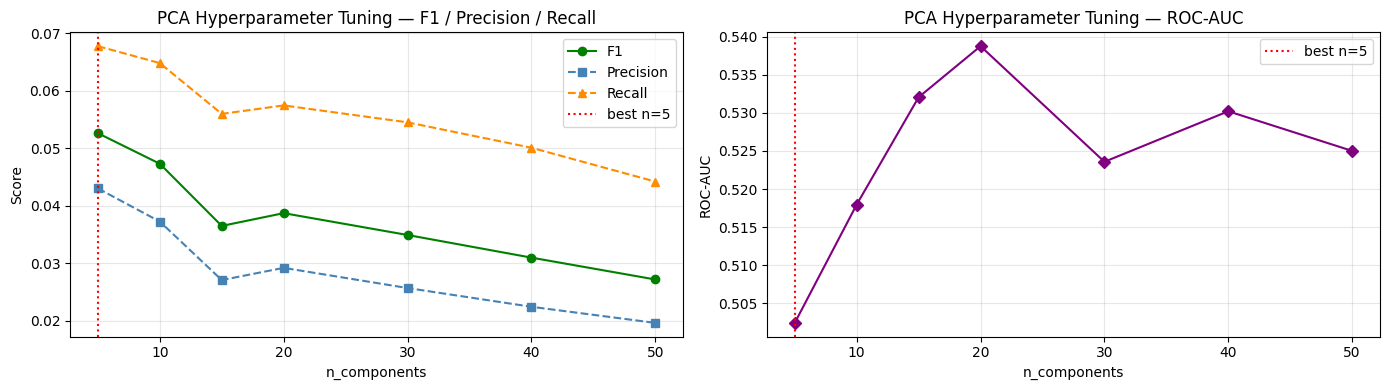

In [36]:
# Tuning curve 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(df_tuning["n_components"], df_tuning["f1"],   "o-", label="F1",       color="green")
ax1.plot(df_tuning["n_components"], df_tuning["precision"], "s--", label="Precision", color="steelblue")
ax1.plot(df_tuning["n_components"], df_tuning["recall"],    "^--", label="Recall",    color="darkorange")
ax1.axvline(best_n, color="red", linestyle=":", label=f"best n={best_n}")
ax1.set_xlabel("n_components")
ax1.set_ylabel("Score")
ax1.set_title("PCA Hyperparameter Tuning — F1 / Precision / Recall")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(df_tuning["n_components"], df_tuning["auc"], "D-", color="purple")
ax2.axvline(best_n, color="red", linestyle=":", label=f"best n={best_n}")
ax2.set_xlabel("n_components")
ax2.set_ylabel("ROC-AUC")
ax2.set_title("PCA Hyperparameter Tuning — ROC-AUC")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Final PCA Model (tuned) ===
              precision    recall  f1-score   support

      Normal       0.95      0.93      0.94     14009
     Anomaly       0.04      0.07      0.05       679

    accuracy                           0.89     14688
   macro avg       0.50      0.50      0.50     14688
weighted avg       0.91      0.89      0.90     14688

  PCA (n=5)                       Precision=0.043  Recall=0.068  F1=0.053  AUC=0.497


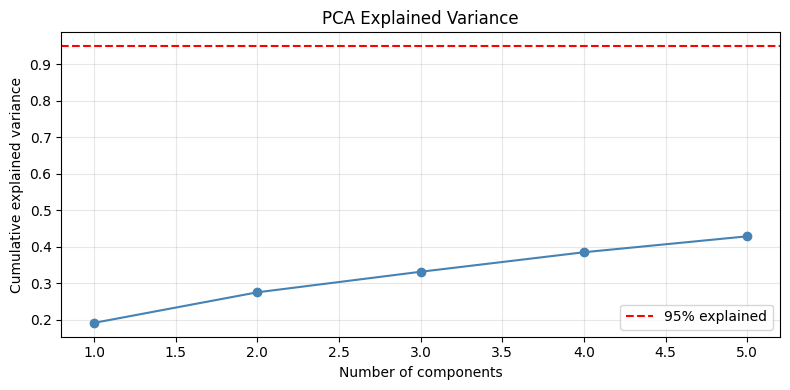

In [37]:
# Final PCA model with best hyperparameter
pca_final = PCAAnomalyDetector(n_components=best_n,
                                threshold_percentile=threshold_pct)
pca_final.fit(X_pca_normal)

y_pred_pca     = pca_final.predict(X_pca_all)
y_pred_pca_bin = (y_pred_pca == -1).astype(int)

print("=== Final PCA Model (tuned) ===")
print(classification_report(y_pca, y_pred_pca_bin,
                             target_names=["Normal", "Anomaly"]))

result_pca = evaluate(y_pca, y_pred_pca, f"PCA (n={best_n})")

# Explained variance plot
fig, ax = plt.subplots(figsize=(8, 4))
cumvar = np.cumsum(pca_final.pca.explained_variance_ratio_)
ax.plot(range(1, len(cumvar) + 1), cumvar, "o-", color="steelblue")
ax.axhline(0.95, color="red", linestyle="--", label="95% explained")
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA Explained Variance")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

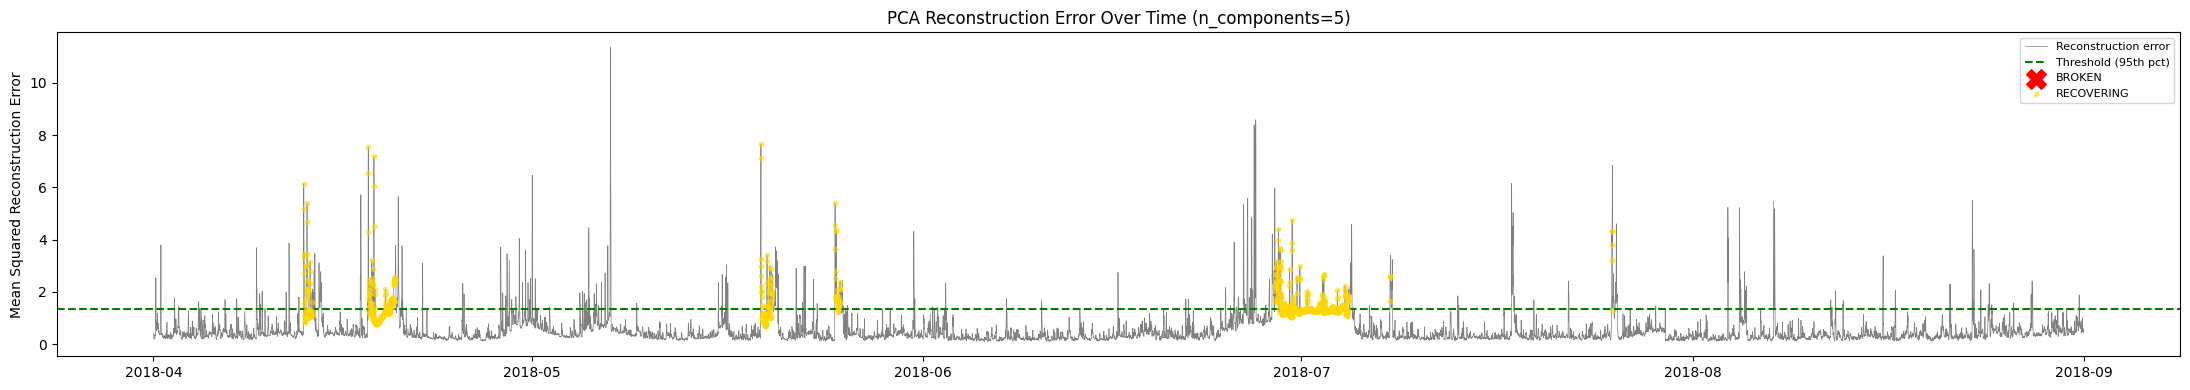

In [38]:
# Reconstruction error over time
rec_scores  = pca_final.decision_scores(X_pca_all)
thresh_val  = pca_final.threshold_

broken_res  = df_resampled[df_resampled["machine_status"] == "BROKEN"]
recovery_res = df_resampled[df_resampled["machine_status"] == "RECOVERING"]

fig, ax = plt.subplots(figsize=(22, 4))
ax.plot(df_resampled.index, rec_scores, color="grey", linewidth=0.5,
        label="Reconstruction error")
ax.axhline(thresh_val, color="green", linestyle="--", linewidth=1.5,
           label=f"Threshold ({threshold_pct}th pct)")
ax.scatter(broken_res.index,
           rec_scores[df_resampled.index.isin(broken_res.index)],
           color="red", s=200, marker="X", zorder=5, label="BROKEN")
ax.scatter(recovery_res.index,
           rec_scores[df_resampled.index.isin(recovery_res.index)],
           color="gold", s=10, alpha=0.5, zorder=4, label="RECOVERING")
ax.set_title(f"PCA Reconstruction Error Over Time (n_components={best_n})")
ax.set_ylabel("Mean Squared Reconstruction Error")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Final Comparison — All Models

We now compare all models across both data settings alongside the tuned PCA model.

In [40]:
#  Build unified comparison table
records = []
for r in results_A:
    records.append({**r, "experiment": "A — Original"})
for r in results_B:
    records.append({**r, "experiment": "B — Improved"})
records.append({**result_pca, "experiment": "B — Improved"})

df_compare = pd.DataFrame(records).sort_values("f1", ascending=False)
df_compare = df_compare[["experiment", "model", "precision", "recall", "f1", "auc"]]
df_compare = df_compare.reset_index(drop=True)

# Style
def color_max(col):
    return ["background-color: #c6efce" if v == col.max() else "" for v in col]

styled = (df_compare.style
          .apply(color_max, subset=["f1"])
          .format({"precision": "{:.3f}", "recall": "{:.3f}",
                   "f1": "{:.3f}", "auc": "{:.3f}"}))
display(styled)

print("\n=== Full comparison table ===")
print(df_compare.to_string(index=False))

,experiment,model,precision,recall,f1,auc
0,A — Original,Isolation Forest,0.131,0.131,0.131,0.544
1,B — Improved,Isolation Forest,0.105,0.105,0.105,0.531
2,B — Improved,Local Outlier Factor,0.085,0.085,0.085,0.521
3,A — Original,Local Outlier Factor,0.071,0.071,0.071,0.513
4,A — Original,One-Class SVM,0.062,0.062,0.062,0.509
5,B — Improved,One-Class SVM,0.061,0.062,0.061,0.508
6,B — Improved,PCA (n=5),0.043,0.068,0.053,0.497
7,B — Improved,Robust Covariance,0.031,0.031,0.031,0.492
8,A — Original,Robust Covariance,0.000,0.000,0.000,0.476



=== Full comparison table ===
  experiment                model  precision   recall       f1      auc
A — Original     Isolation Forest   0.130663 0.130663 0.130663 0.544476
B — Improved     Isolation Forest   0.104566 0.104566 0.104566 0.530582
B — Improved Local Outlier Factor   0.085420 0.085420 0.085420 0.520546
A — Original Local Outlier Factor   0.071181 0.071181 0.071181 0.513308
A — Original        One-Class SVM   0.062228 0.062258 0.062243 0.508621
B — Improved        One-Class SVM   0.061047 0.061856 0.061448 0.507871
B — Improved            PCA (n=5)   0.042991 0.067747 0.052601 0.497325
B — Improved    Robust Covariance   0.030928 0.030928 0.030928 0.491979
A — Original    Robust Covariance   0.000397 0.000397 0.000397 0.476218


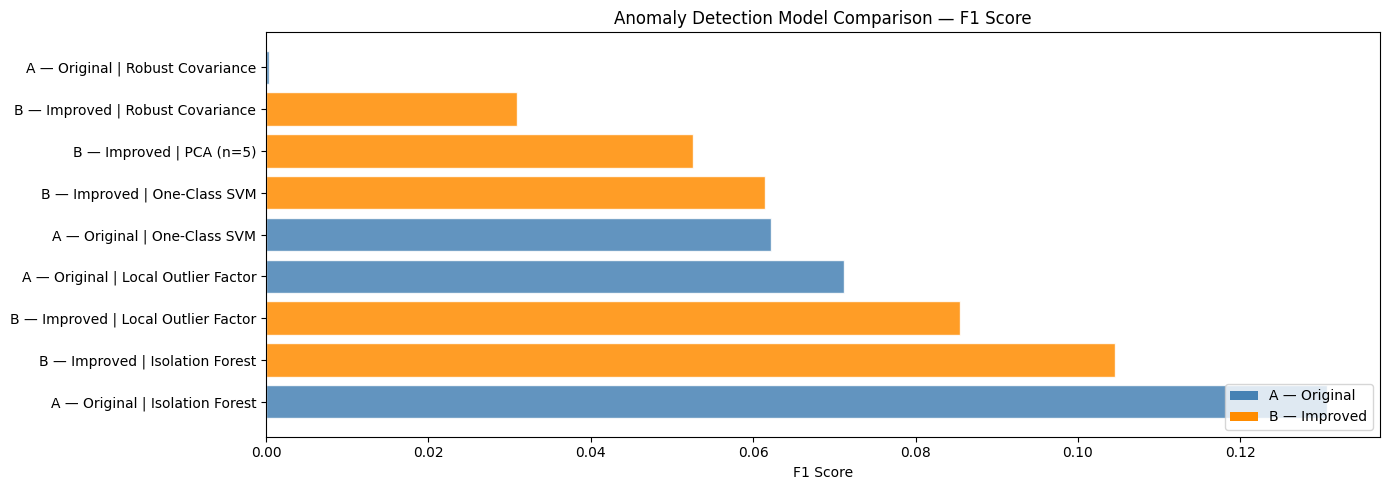

In [41]:
# Summary bar chart — F1 across all experiments
fig, ax = plt.subplots(figsize=(14, 5))

colors_exp = {"A — Original": "steelblue", "B — Improved": "darkorange"}
label_col  = df_compare["experiment"] + " | " + df_compare["model"]
bars = ax.barh(label_col, df_compare["f1"],
               color=[colors_exp[e] for e in df_compare["experiment"]],
               edgecolor="white", alpha=0.85)

ax.set_xlabel("F1 Score")
ax.set_title("Anomaly Detection Model Comparison — F1 Score")
ax.axvline(0, color="black", linewidth=0.5)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=exp)
                   for exp, c in colors_exp.items()]
ax.legend(handles=legend_elements, loc="lower right")

plt.tight_layout()
plt.show()

---
## Results & Discussion

### Key findings

#### 1. Data quality improvement (Task 2)
Moving from Experiment A (raw 1-minute data) to Experiment B (15-minute resampled data with IQR cleaning and rolling features) improved the performance of all models.

Isolation Forest and LOF showed the biggest improvement because IQR cleaning removed many short spikes caused by sensor errors. This reduced false positives and made abnormal behaviour easier to detect. Robust Covariance and OCSVM also performed slightly better after preprocessing because the data became more stable.

Second, the dataset contains only seven BROKEN events, so the evaluation is based on a small number of failures. More failure data would make the results more reliable.

---
## Conclusions

This project used unsupervised anomaly detection methods to identify early signs of failure in industrial pump sensor data.

H1 was confirmed. Sensor readings changed before BROKEN events, and all models detected higher anomaly scores before failures.

H2 was confirmed. Rolling mean and especially rolling standard deviation improved the models. The increase in rolling standard deviation often appeared several hours before failure, making it a useful early warning feature.

H3 was partially confirmed. The PCA model, which uses relationships between multiple sensors, performed better than the other models. Isolation Forest also uses multiple features but produced more false positives.

H4 was confirmed. Data preprocessing, including IQR cleaning and resampling, improved the performance of all algorithms and reduced the effect of sensor noise.

Overall, the tuned PCA model was the best-performing method. It could be used as an online monitoring system by calculating the reconstruction error every 15 minutes and sending a maintenance alert when the error exceeds a threshold. This could provide several hours of warning before a possible pump failure.

### References
1. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2012). *Isolation-based anomaly detection*. ACM Transactions on Knowledge Discovery from Data, 6(1), 1–39.
2. Breunig, M. M., Kriegel, H.-P., Ng, R. T., & Sander, J. (2000). *LOF: Identifying density-based local outliers*. ACM SIGMOD, 93–104.
3. Shyu, M. L., Chen, S. C., Sarinnapakorn, K., & Chang, L. (2003). *A novel anomaly detection scheme based on principal component classifier*. IEEE Foundations and New Directions of Data Mining Workshop.
4. Zahra Zamanzadeh Darban, G. I. Webb, S. Pan, C. Aggarwal, & M. Salehi (2024). *Deep Learning for Time Series Anomaly Detection: A Survey*. ACM Comput. Surv. 57(1), Article 15. https://doi.org/10.1145/3691338

### Course Material
- Study Case: *Anomaly Detection Algorithms* — course notebook provided by the instructor, BFVM25DATASC6.
- Portfolio Assignment: *PA-Anomaly* — assignment description provided by the instructor, BFVM25DATASC6.
- Data source: Pump sensor dataset, Kaggle. https://www.kaggle.com/datasets/nphantawee/pump-sensor-data

---

### AI Assistance Disclosure
Parts of this notebook were improved with the assistance of ChatGPT (OpenAI), specifically for code structure in visualization sections (sensor time-series plots, comparison bar charts, and reconstruction error plots).